In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
train_files_healthy = "/content/drive/MyDrive/Data/Train/Healthy"
train_files_powdery = "/content/drive/MyDrive/Data/Train/Powdery"
train_files_rust = "/content/drive/MyDrive/Data/Train/Rust"

In [4]:
test_files_healthy = "/content/drive/MyDrive/Data/Test/Healthy"
test_files_powdery = "/content/drive/MyDrive/Data/Test/Powdery"
test_files_rust = "/content/drive/MyDrive/Data/Test/Rust"

In [5]:
valid_files_healthy = "/content/drive/MyDrive/Data/Validation/Healthy"
valid_files_powdery = "/content/drive/MyDrive/Data/Validation/Powdery"
valid_files_rust = "/content/drive/MyDrive/Data/Validation/Rust"

In [6]:
import os
def total_files(folder_path):
    num_files = len([f for f in os.listdir(folder_path) if os.path.isfile(os.path.join(folder_path, f))])
    return num_files

print("Number of healthy leaf images in training set", total_files(train_files_healthy))
print("Number of powder leaf images in training set", total_files(train_files_powdery))
print("Number of rusty leaf images in training set", total_files(train_files_rust))

print("========================================================")

print("Number of healthy leaf images in test set", total_files(test_files_healthy))
print("Number of powder leaf images in test set", total_files(test_files_powdery))
print("Number of rusty leaf images in test set", total_files(test_files_rust))

print("========================================================")

print("Number of healthy leaf images in validation set", total_files(valid_files_healthy))
print("Number of powder leaf images in validation set", total_files(valid_files_powdery))
print("Number of rusty leaf images in validation set", total_files(valid_files_rust))

Number of healthy leaf images in training set 458
Number of powder leaf images in training set 430
Number of rusty leaf images in training set 434
Number of healthy leaf images in test set 50
Number of powder leaf images in test set 50
Number of rusty leaf images in test set 45
Number of healthy leaf images in validation set 20
Number of powder leaf images in validation set 20
Number of rusty leaf images in validation set 20


Image of a heatlthy plant


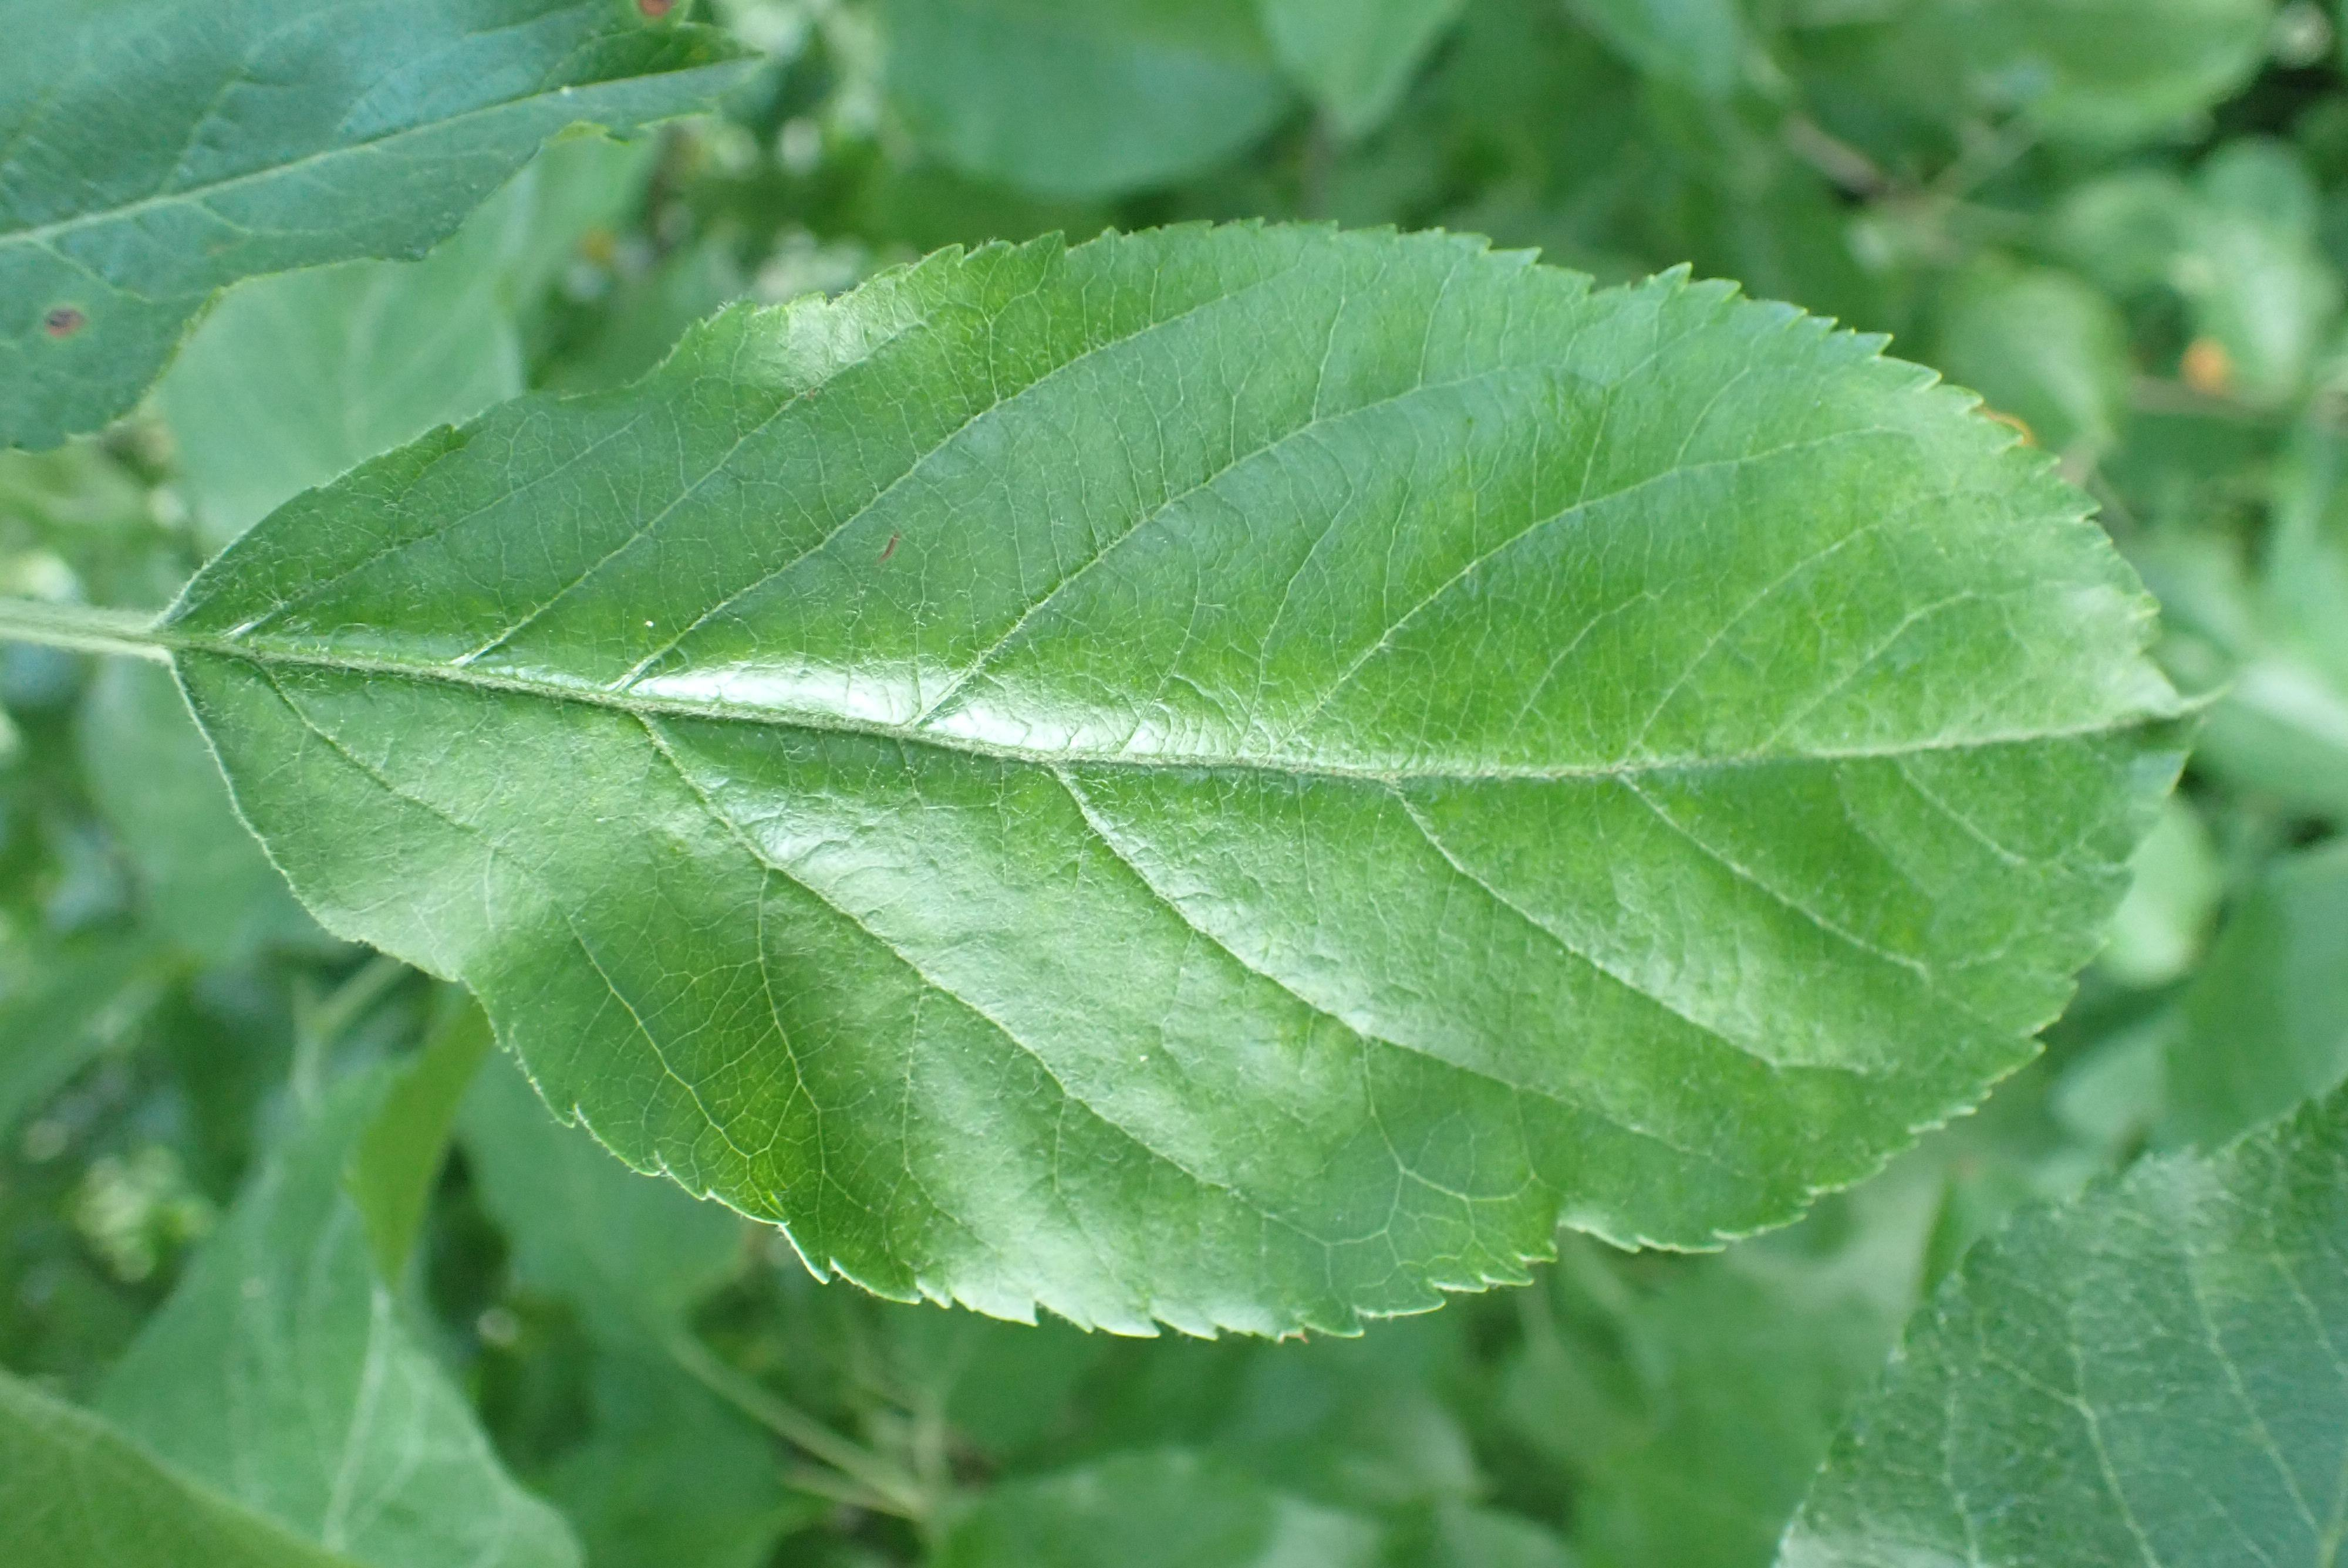

In [7]:
from PIL import Image
import IPython.display as display

image_path = '/content/drive/MyDrive/Data/Train/Healthy/8ce77048e12f3dd4.jpg'

print("Image of a heatlthy plant")
with open(image_path, 'rb') as f:
    display.display(display.Image(data=f.read(), width=500))

Image of a rust plant


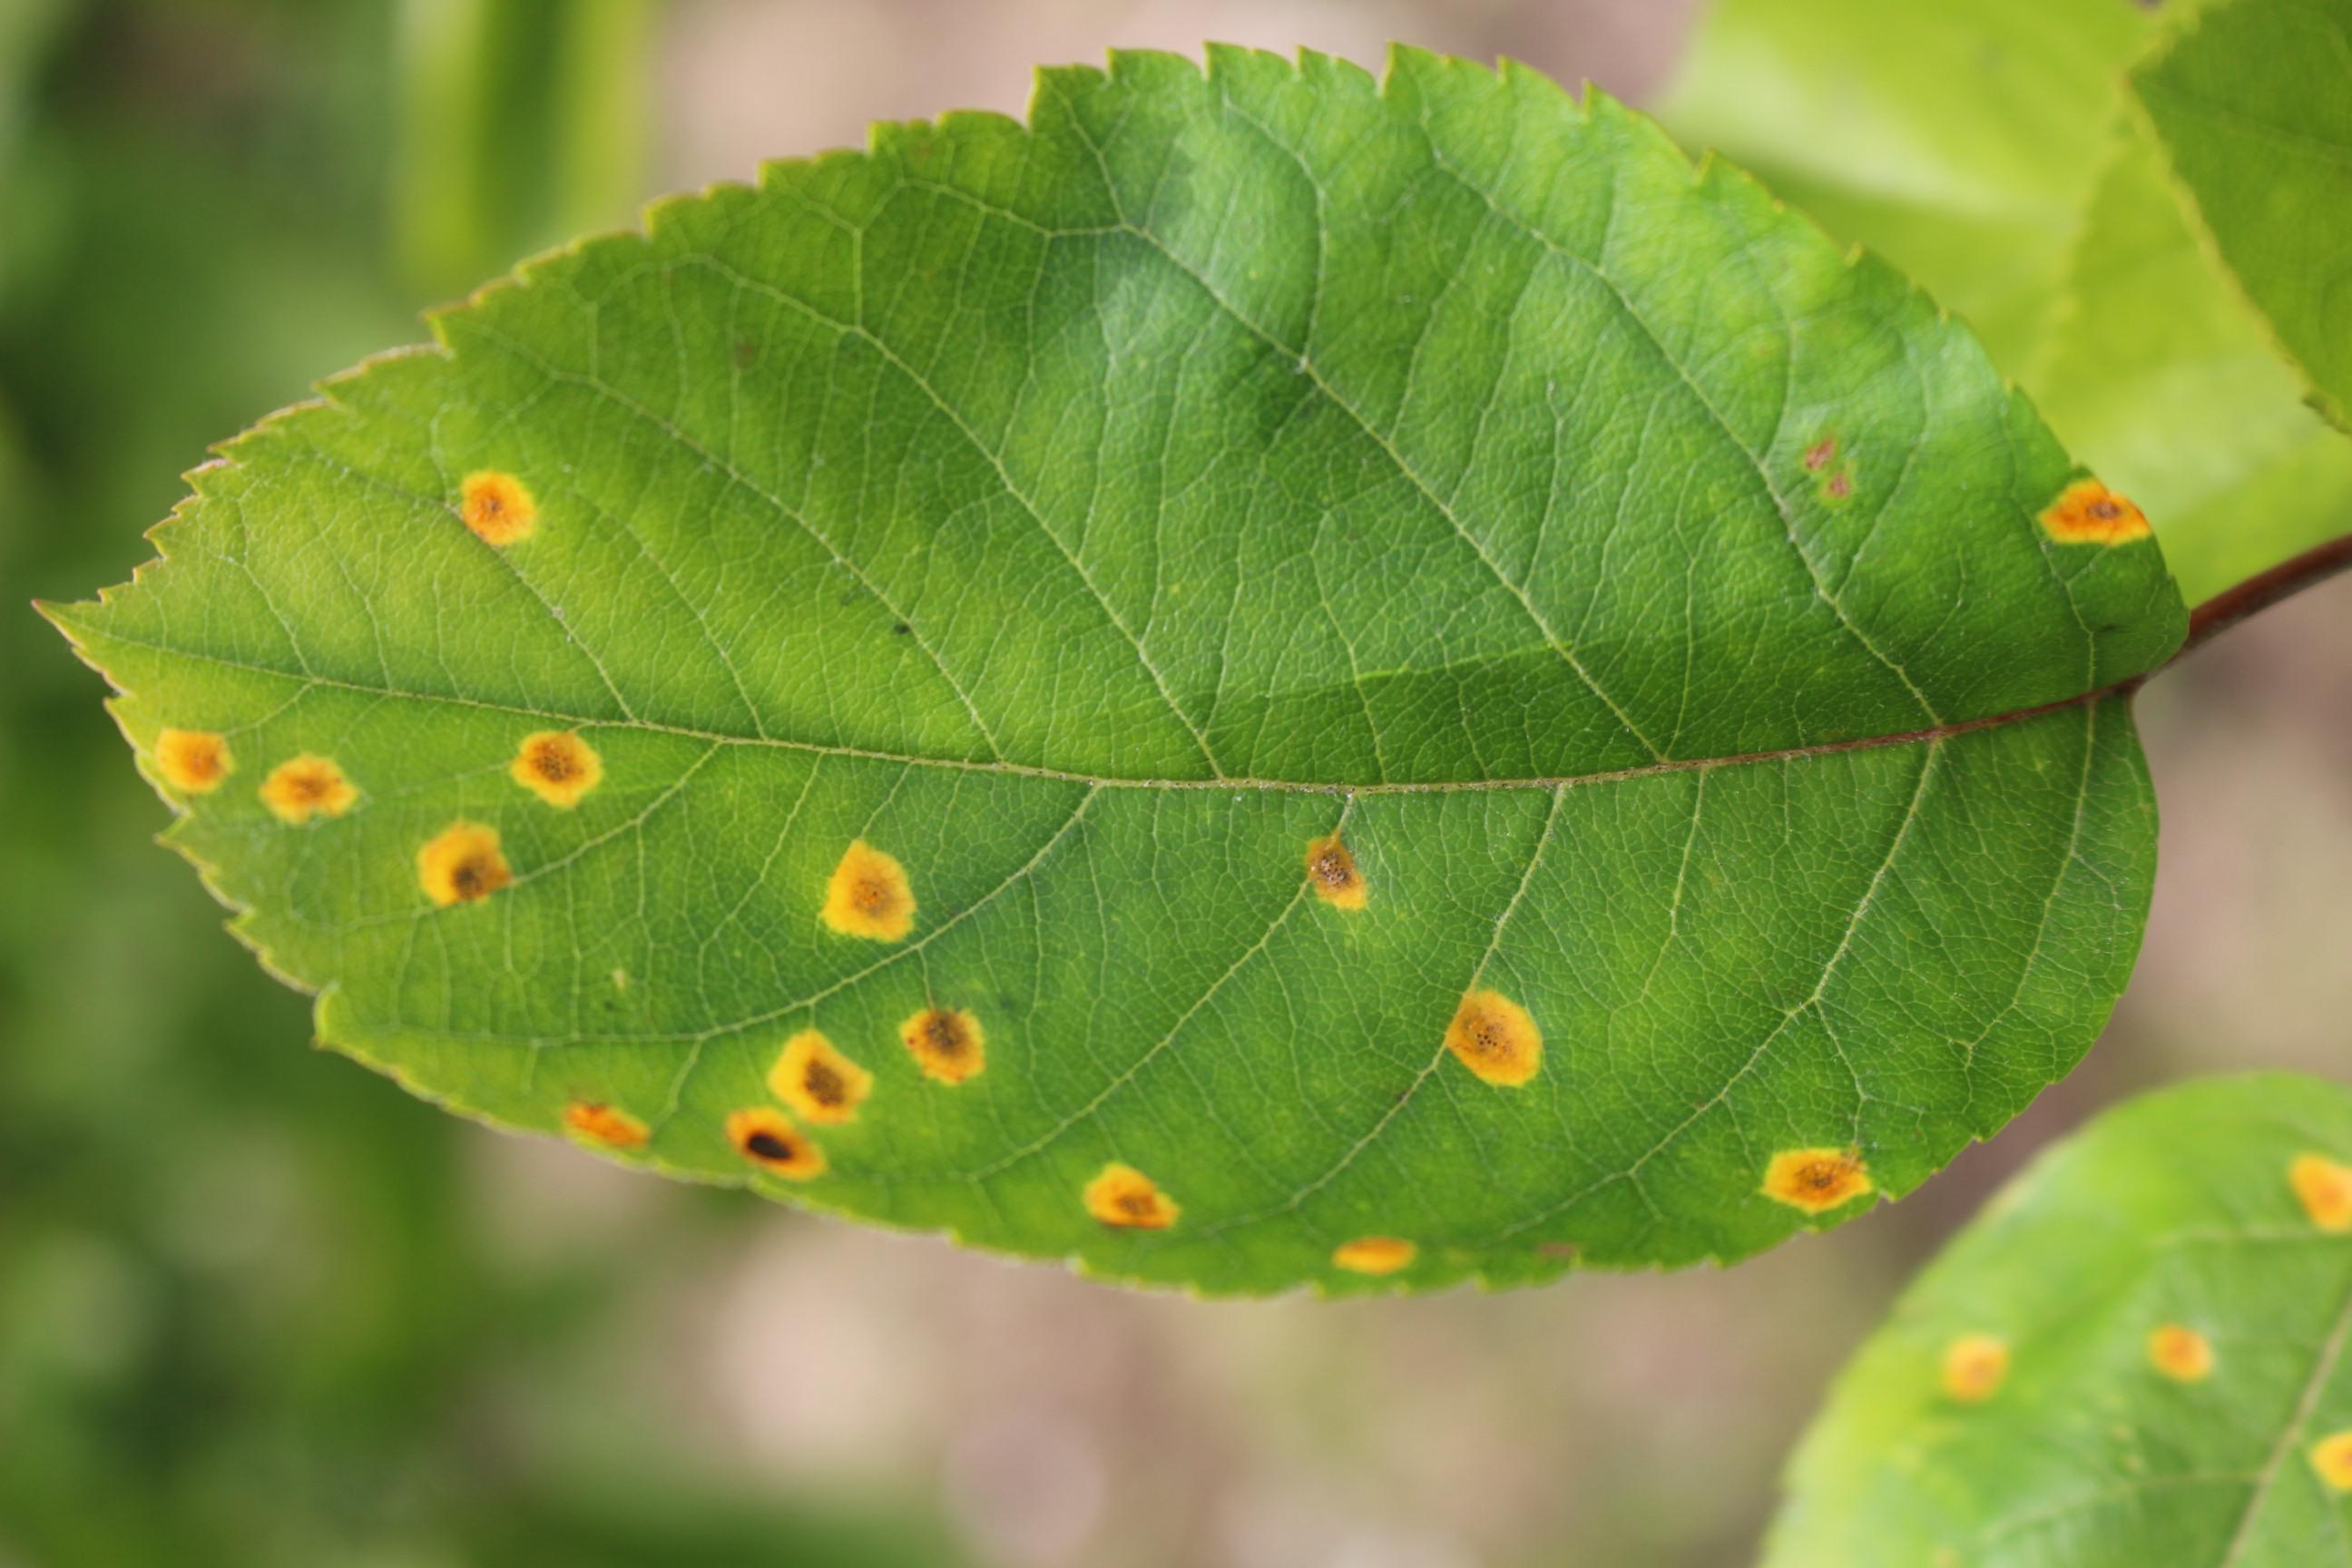

In [8]:
print("Image of a rust plant")
image_path = '/content/drive/MyDrive/Data/Train/Rust/80f09587dfc7988e.jpg'

with open(image_path, 'rb') as f:
    display.display(display.Image(data=f.read(), width=500))

Image of powdery plant


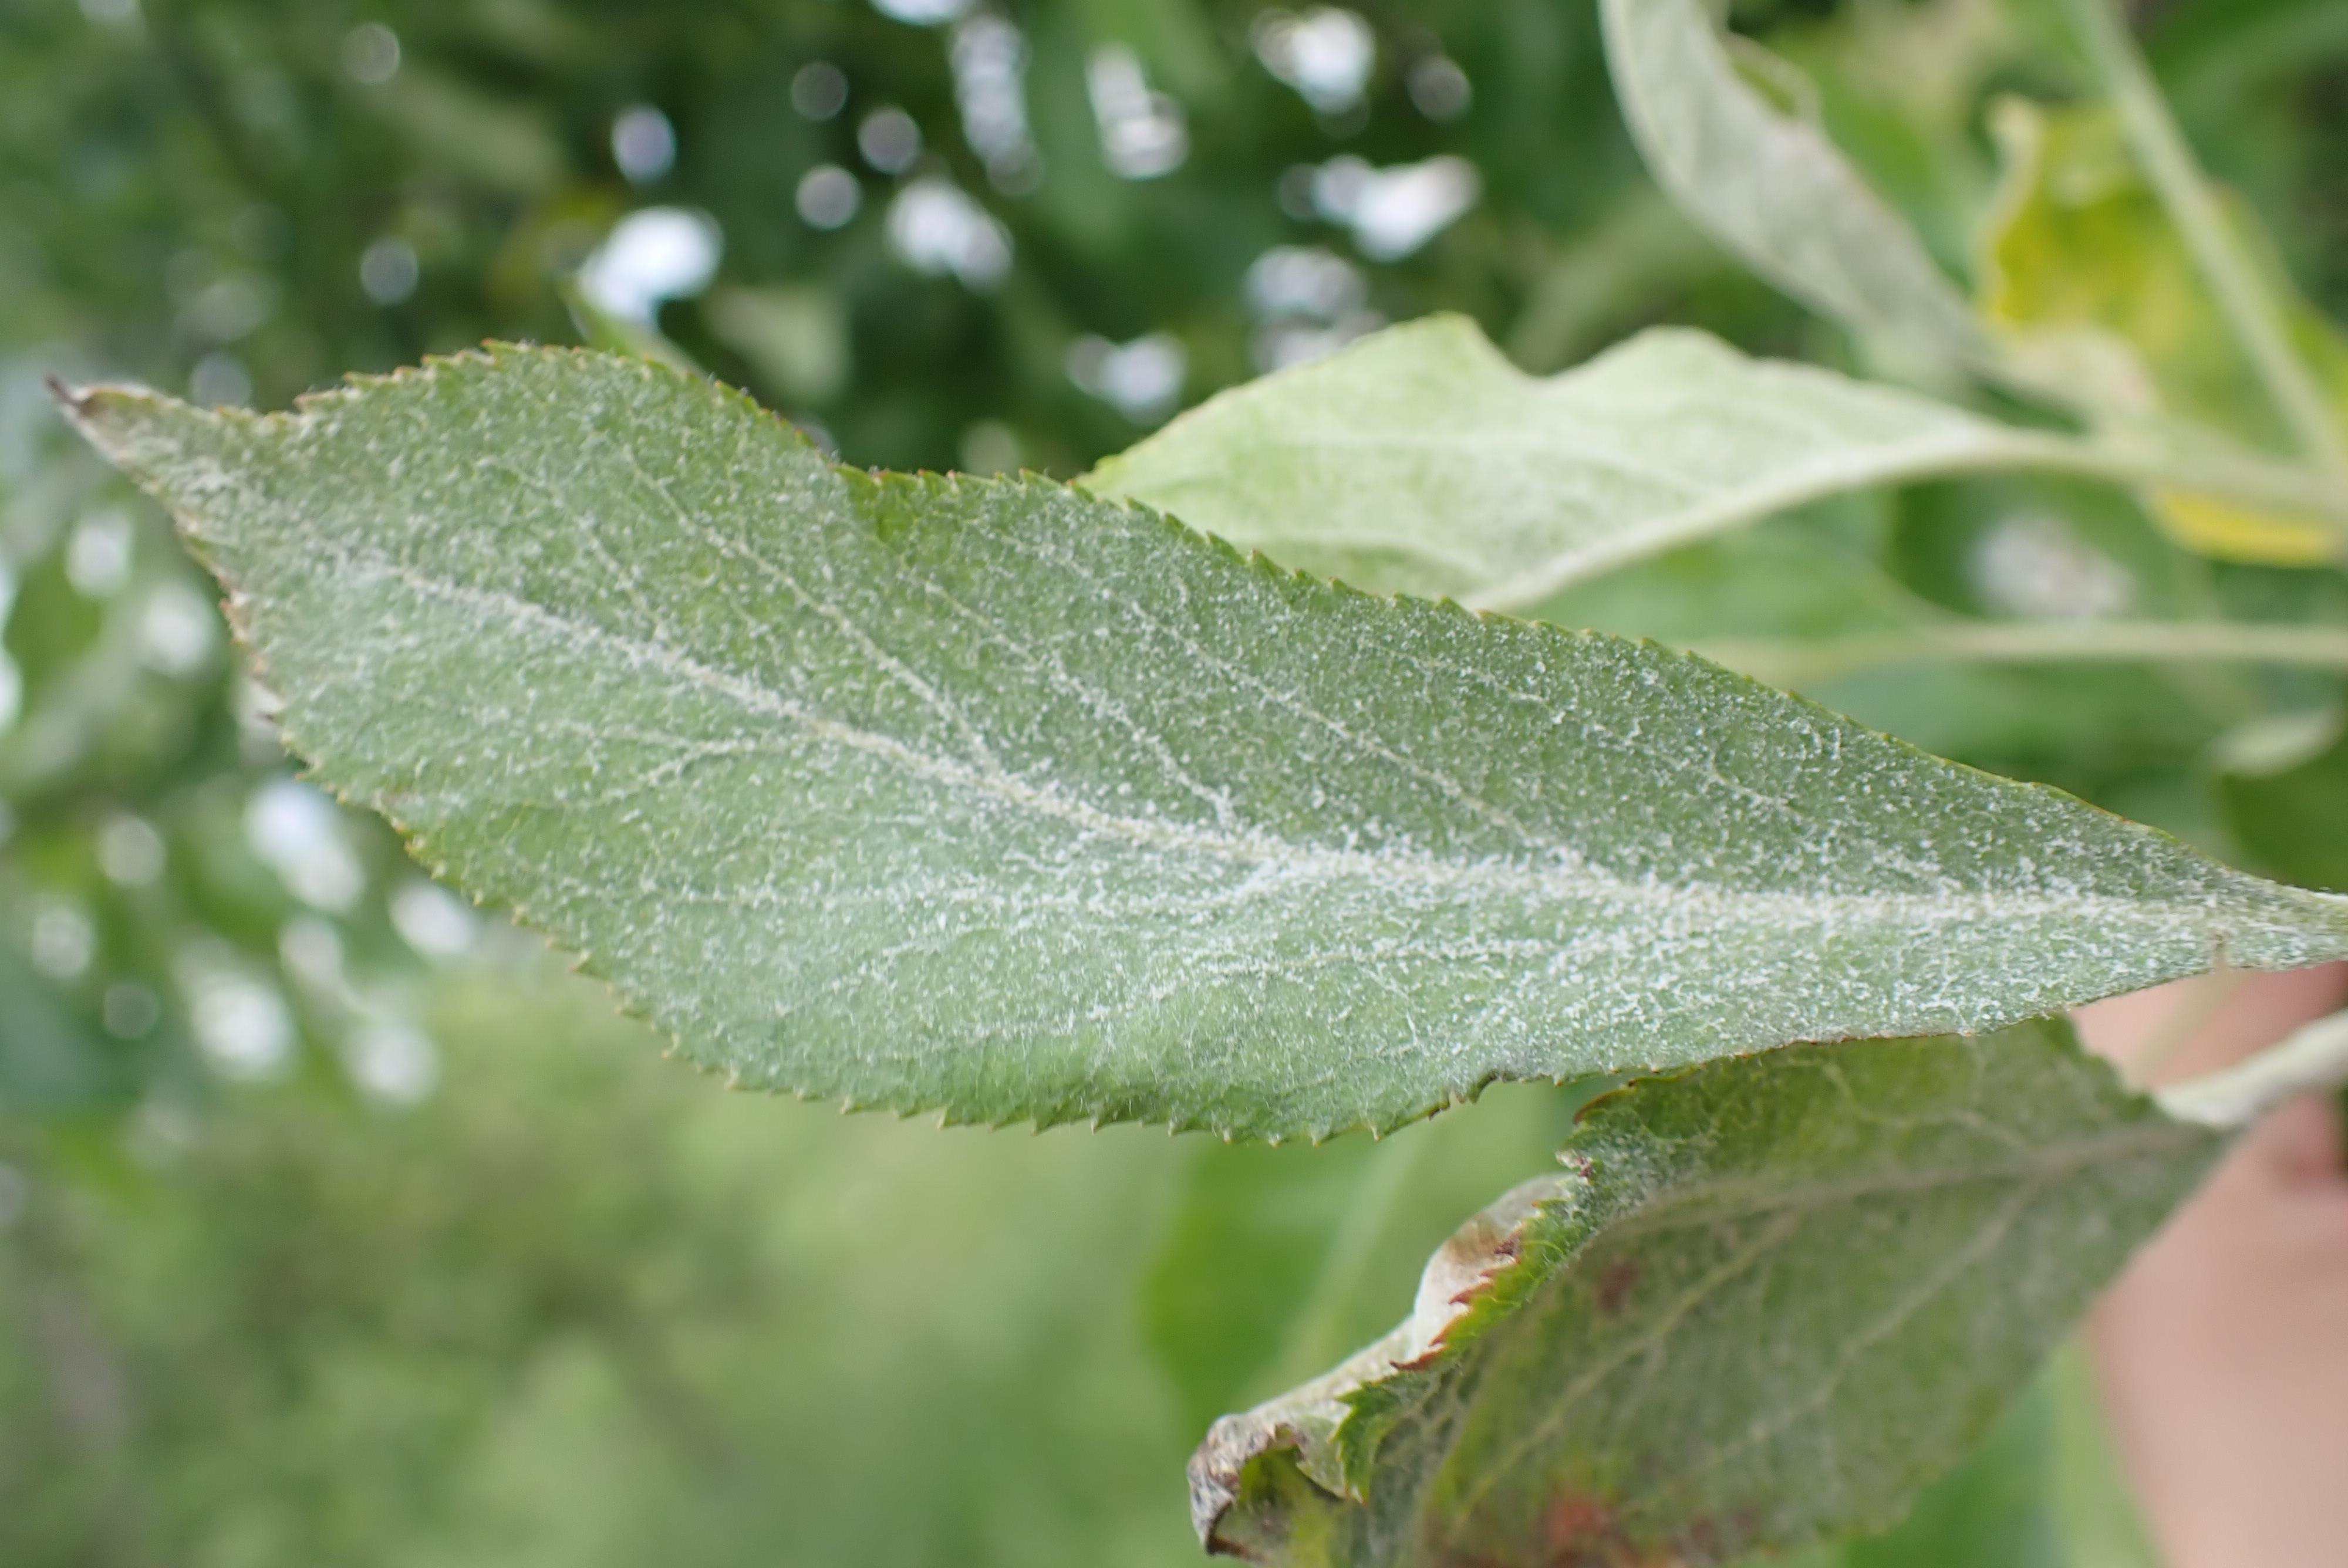

In [9]:
print("Image of powdery plant")
image_path = '/content/drive/MyDrive/Data/Train/Powdery/81352f0c4c5efa9b.jpg'

with open(image_path, 'rb') as f:
    display.display(display.Image(data=f.read(), width=500))

In [10]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Create the training data generator with data augmentation
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

# Create the validation data generator without augmentation
test_datagen = ImageDataGenerator(
    rescale=1.0 / 255
)

# Load training images
train_generator = train_datagen.flow_from_directory(
    '/content/drive/MyDrive/Data/Train',
    target_size=(225, 225),
    batch_size=32,
    class_mode='categorical'
)

# Load validation images
validation_generator = test_datagen.flow_from_directory(
    '/content/drive/MyDrive/Data/Validation',
    target_size=(225, 225),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

# Display class information
print("Class indices:", train_generator.class_indices)
print("Number of training images:", train_generator.samples)
print("Number of validation images:", validation_generator.samples)

Found 1322 images belonging to 3 classes.
Found 60 images belonging to 3 classes.
Class indices: {'Healthy': 0, 'Powdery': 1, 'Rust': 2}
Number of training images: 1322
Number of validation images: 60


In [11]:
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense


model = Sequential()

model.add(Conv2D(32, (3, 3), input_shape=(225, 225, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))


model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Flatten())
model.add(Dense(64, activation='relu'))
model.add(Dense(3, activation='softmax'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [12]:
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [13]:
history = model.fit(train_generator,
                    batch_size=16,
                    epochs=10,
                    validation_data=validation_generator,
                    validation_batch_size=16
                    )

Epoch 1/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 465s 11s/step - accuracy: 0.5424 - loss: 0.9883 - val_accuracy: 0.7333 - val_loss: 0.6474
Epoch 2/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 108s 3s/step - accuracy: 0.8109 - loss: 0.4486 - val_accuracy: 0.8500 - val_loss: 0.4815
Epoch 3/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 109s 3s/step - accuracy: 0.9039 - loss: 0.2781 - val_accuracy: 0.8167 - val_loss: 0.5047
Epoch 4/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 108s 3s/step - accuracy: 0.9054 - loss: 0.2621 - val_accuracy: 0.7667 - val_loss: 0.4928
Epoch 5/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 108s 3s/step - accuracy: 0.9107 - loss: 0.2467 - val_accuracy: 0.9000 - val_loss: 0.2740
Epoch 6/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 108s 3s/step - accuracy: 0.9463 - loss: 0.1615 - val_accuracy: 0.8833 - val_loss: 0.4505
Epoch 7/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 106s 3s/step - accuracy: 0.9289 - loss: 0.2103 - val_accuracy: 0.9000 - val_loss: 0.2977
Epoch 8/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 115s 3s/step - accuracy: 0.9576 - loss: 0.1592 - val_accuracy: 0.8333 - 

In [15]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 223, 223, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 43264)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     2,768,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,476,427 (32.34 MB)

 Trainable params: 2,825,475 (10.78 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 5,650,952 (21.56 MB)

In [16]:
model.save("model.keras")
print("Model saved successfully!")

Model saved successfully!


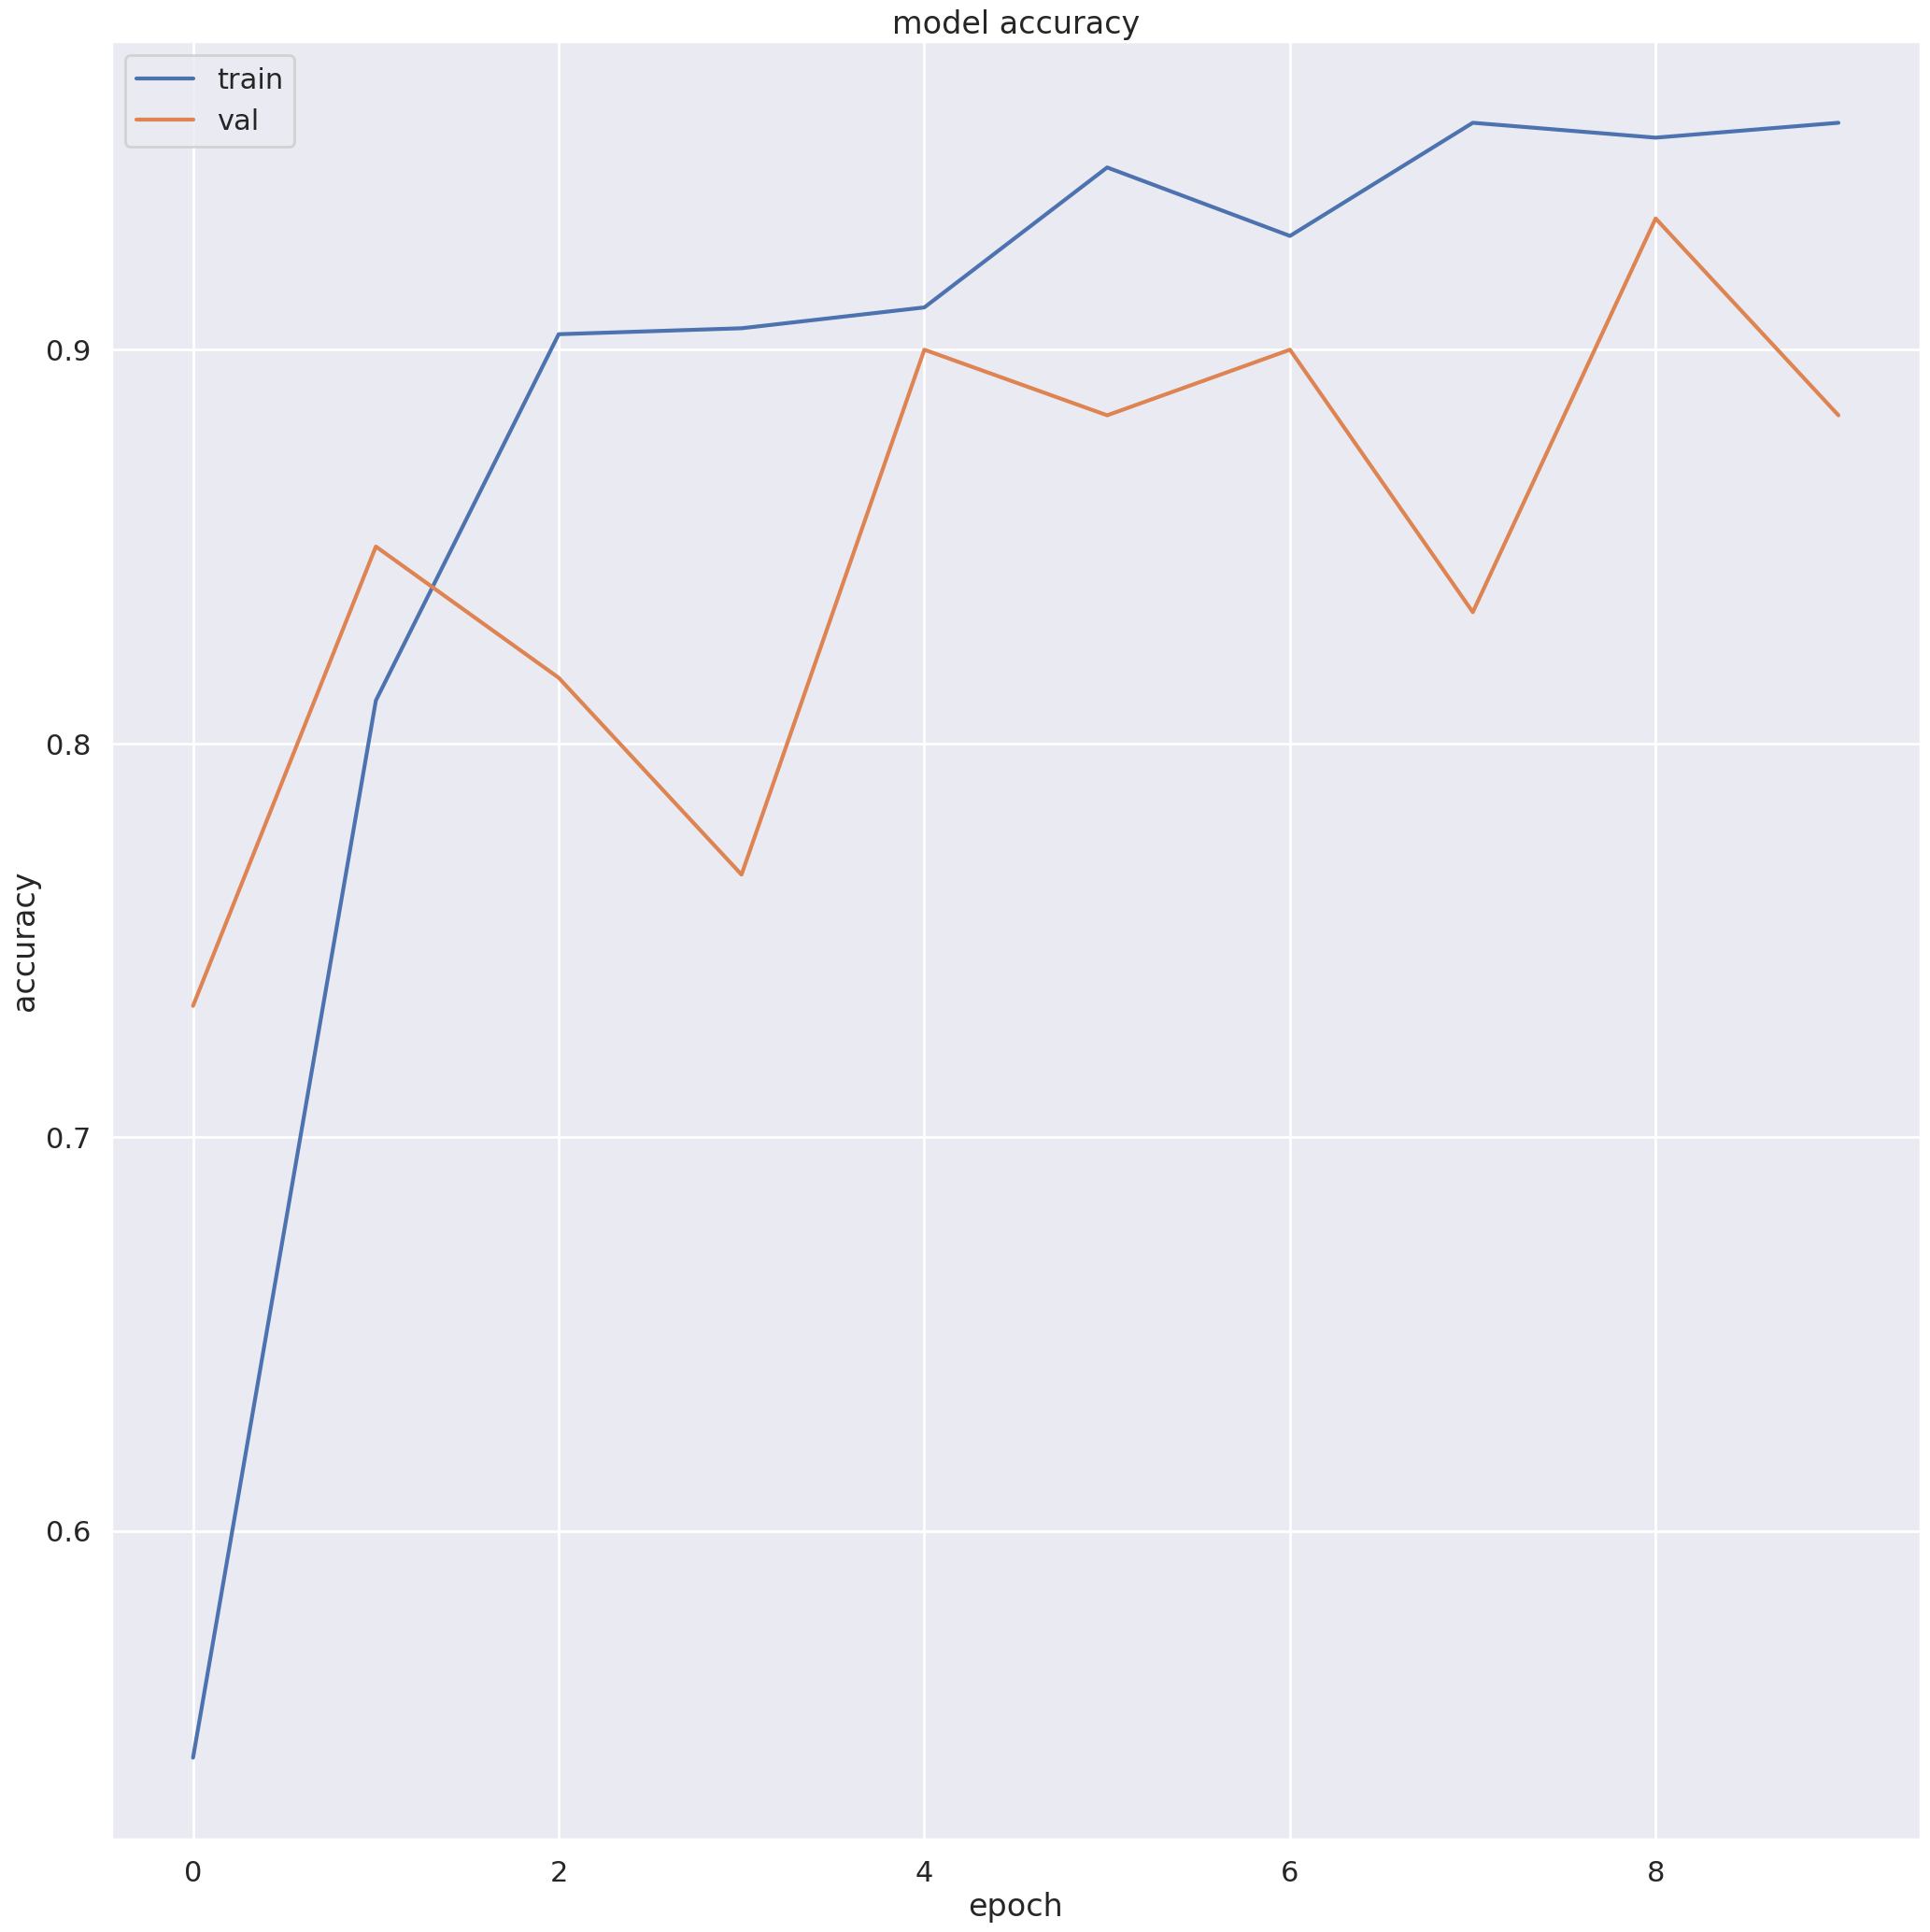

In [17]:
from matplotlib import pyplot as plt
from matplotlib.pyplot import figure

import seaborn as sns
sns.set_theme()
sns.set_context("poster")

figure(figsize=(25, 25), dpi=100)

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

In [18]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np

def preprocess_image(image_path, target_size=(225, 225)):
    img = load_img(image_path, target_size=target_size)
    x = img_to_array(img)
    x = x.astype('float32') / 255.
    x = np.expand_dims(x, axis=0)
    return x

x = preprocess_image('/content/drive/MyDrive/Data/Test/Rust/83a75e2de0cb984b.jpg')

In [19]:
predictions = model.predict(x)
predictions[0]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


array([3.1449454e-25, 1.3976057e-19, 1.0000000e+00], dtype=float32)

In [20]:
labels = train_generator.class_indices
labels = {v: k for k, v in labels.items()}
labels

{0: 'Healthy', 1: 'Powdery', 2: 'Rust'}

In [21]:
predicted_label = labels[np.argmax(predictions)]
print(predicted_label)

Rust
